![Banner](../images/09_03_banner_rs_rader.png)


# Sentinel-1 Based Indices

Sentinel-1-based indices are mathematical measures derived from Synthetic Aperture Radar (SAR) data collected by the European Space Agency's (ESA) Sentinel-1 satellite mission.


## Overview

They help researchers characterize the Earth's surface, monitor vegetation and agricultural fields, detect flooding, assess soil moisture conditions, map wetlands, and measure changes in land cover.

Unlike optical satellites such as Sentinel-2 and Landsat, Sentinel-1 uses radar signals, so it can collect observations during both day and night and through clouds. This makes it particularly useful in tropical and monsoon regions such as Bangladesh, where persistent cloud cover often limits optical satellite observations.

One important distinction: Sentinel-1 does not have a single universally accepted set of indices comparable to NDVI for optical imagery. Instead, researchers calculate several radar backscatter metrics, polarization ratios, polarimetric features, and temporal change indicators, depending on the application and the available data.


## Core concepts

### Learning objectives

1. Explain what VV and VH backscatter record, and compute the cross-polarization ratio VH/VV from linear sigma0.
2. Calculate the dual-pol Radar Vegetation Index, RVI4S1, the Radar Forest Degradation Index, the Sentinel Normalized Index, PRVI and DPSVI from linear VV and VH.
3. Map those indices on the Sentinel-1 IW GRD window of Cox's Bazar to Teknaf on 13 January 2024, including one call to `dual_pol_indices`.
4. Follow scene-mean RVI and RFDI from 3 January to 23 November 2017 on the track 77 stack over Kutupalong-Balukhali, for both sigma0 and RTC gamma0, and check the identity RVI = 2(1 - RFDI).
5. Apply `temporal_change` and `temporal_ratio` to the RADARSAT-2 HH/HV pair of 16 November 2023 (Standard beam S3) and 30 November 2023 (Wide beam W3) over northern Germany.
6. Choose indices for crop growth, flood and water mapping, forest degradation, and soil moisture.

### Contents

1. Understanding Sentinel-1 data
2. Major Sentinel-1-based indices
3. Other useful Sentinel-1-derived metrics
4. Which indices should you use?
5. Worked example: Cox's Bazar, 13 January 2024
6. Temporal change in RVI and the forest degradation index
7. Recommended reading and technical references


## Understanding Sentinel-1 data

Sentinel-1 is a radar Earth-observation mission operated by the European Space Agency. Its C-band radar operates at approximately 5.405 GHz, corresponding to a wavelength of about 5.55 cm.


### The two main polarization channels

Sentinel-1 commonly provides dual-polarization data in Interferometric Wide (IW) swath mode over land.

| Polarization | Meaning                                              | Common applications                                                  |
| ------------ | ---------------------------------------------------- | -------------------------------------------------------------------- |
| VV           | Vertical transmission, vertical reception            | Soil surface conditions, flooding, urban areas, vegetation structure |
| VH           | Vertical transmission, horizontal reception          | Vegetation volume scattering, crop growth, forest structure          |
| VV/VH        | Ratio of co-polarized to cross-polarized backscatter | Crop structure, vegetation changes, surface characterization         |
| VH/VV        | Inverse polarization ratio                           | Vegetation-related comparisons and empirical crop indicators         |

The availability of channels depends on the acquisition mode and product. VV and VH are widely used for land monitoring, particularly over agricultural regions.


### What is radar backscatter?

Radar backscatter describes how much of the transmitted radar energy returns to the satellite after interacting with the Earth's surface.

It is commonly represented by the normalized radar cross-section, \\(\sigma^0\\) (sigma naught).

- High backscatter: May occur over rough surfaces, buildings, or vegetation with strong scattering.
- Low backscatter: May occur over smooth, calm water or smooth surfaces that reflect radar energy away from the satellite.
- Intermediate backscatter: Can occur over bare soil, cropland, grassland, and other surfaces, depending on their characteristics.

These are general patterns, not universal rules. Soil moisture, vegetation density, surface roughness, incidence angle, and radar polarization all affect the signal.

Sentinel-1 indices are built from these measurements.


## Major Sentinel-1-based indices

The following indices and features are widely used in SAR remote sensing. Some are established indices, while others are simple derived metrics commonly used as predictors in machine-learning models.

**Notation:** `VV` and `VH` below denote calibrated, linear-scale backscatter unless otherwise specified.


### Backscatter intensity: VV and VH

These are the foundational Sentinel-1 variables from which many other indices are derived.

#### VV backscatter

$$\sigma^0_\mathrm{VV}$$

Measures co-polarized radar backscatter. It is sensitive to surface roughness, soil moisture, buildings, and vegetation-ground interactions.

#### VH backscatter

$$\sigma^0_\mathrm{VH}$$

Measures cross-polarized backscatter, which is often sensitive to volume scattering from vegetation and changes in crop structure.

_Applications_: crop monitoring, land-cover classification, surface-water mapping, and detecting changes in land-surface conditions.

For example, increasing VH backscatter during a rice-growing season can indicate increasing vegetation structure. However, the relationship depends on crop stage, water conditions, planting density, and acquisition geometry.


### VH/VV cross-polarization ratio

`Vegetation and crop monitoring`

The cross-polarization ratio compares cross-polarized backscatter with co-polarized backscatter.

**Cross-Pol Ratio:**  

$$
CR = \frac{VH}{VV}
$$

A logarithmic equivalent is the difference between the dB values:

$$
CR_\mathrm{dB} = VH_\mathrm{dB} - VV_\mathrm{dB}
$$

**Interpretation**

- Higher values may indicate stronger cross-polarized scattering relative to co-polarized scattering.
- Lower values may indicate relatively stronger surface or co-polarized scattering.
- Seasonal changes can help characterize vegetation growth and crop development.

This ratio is used in crop monitoring and land-cover characterization. It is not a direct measurement of vegetation health, and its response varies with surface moisture, crop structure, and viewing geometry.


### Radar Vegetation Index (RVI)

`Crop growth`

The Radar Vegetation Index is among the most commonly used Sentinel-1-derived vegetation indices.

A widely used dual-polarization formulation for Sentinel-1 is:

$$\boxed{\mathrm{RVI}=\frac{4VH}{VV+VH}}$$

Here, both inputs must be in linear power units.

What does it measure?

RVI uses the relative contribution of cross-polarized scattering to characterize vegetation-related scattering. It is often used as an indicator of crop structure and vegetation development.

Typical applications

- Rice growth monitoring.
- Crop phenology and seasonal development.
- Vegetation mapping.
- Agricultural classification and yield modeling.
- Time-series monitoring of vegetation changes.

Interpretation: Higher values can indicate stronger cross-polarized scattering relative to total measured backscatter under comparable conditions.

Important formula distinction: This particular equation can theoretically range from 0 to 4, not 0 to 1. Other RVI formulations and rescaled variants exist. Always record which RVI definition is used in a study.&#x20;


### Sentinel-1 Radar Vegetation Index (RVI4S1)

RVI4S1 is another formulation specifically adapted for Sentinel-1 dual-polarization observations.

$$\boxed{ \mathrm{RVI4S1} = \sqrt{\frac{VV}{VV+VH}} \frac{4VH}{VV+VH} }$$

This formulation combines the polarization contribution with a weighting term based on the relative VV backscatter.

Applications

- Monitoring crop development through time.
- Comparing crop growth stages.
- Building vegetation-related predictors for machine learning.
- Studying seasonal variation in agricultural landscapes.

RVI4S1 should not be confused with the simpler dual-polarization RVI. Their numerical values and interpretation can differ even when calculated from the same image.&#x20;


### Radar Forest Degradation Index (RFDI)

Forest condition

A commonly used dual-polarization version is:

$$\boxed{\mathrm{RFDI}=\frac{VV-VH}{VV+VH}}$$

This normalized measure compares co-polarized and cross-polarized backscatter.

Applications

- Forest degradation monitoring.
- Forest disturbance assessment.
- Tracking changes in forest cover.
- Supporting deforestation and land-cover change analysis.

In some established applications, lower RFDI values are associated with denser forests, while higher values may indicate more degraded or less vegetated surfaces. These thresholds are context-dependent and should be calibrated to the forest type and local conditions.

RFDI can produce misleading interpretations over water, cities, bare ground, or other areas without forest vegetation.&#x20;


### Sentinel Normalized Index (SNI)

A normalized polarization contrast can be calculated as:

$$\boxed{\mathrm{SNI}=\frac{VH-VV}{VH+VV}}$$

This expression compares the two polarization channels on a normalized scale.

Potential uses

- Crop and vegetation classification.
- Comparing radar scattering characteristics between land-cover types.
- Monitoring seasonal polarization changes.
- Developing features for land-cover and crop-mapping models.

With positive linear backscatter inputs, SNI generally lies between −1 and +1. Values closer to +1 indicate a relatively greater VH contribution; values closer to −1 indicate a relatively greater VV contribution.

SNI is not a direct equivalent of the optical Normalized Difference Vegetation Index (NDVI).


### Polarimetric Radar Vegetation Index (PRVI)

PRVI is a vegetation-related metric whose definition varies across publications.

One formulation used in Sentinel-1 research is:

$$\boxed{ \mathrm{PRVI} = \left(1-\frac{VV}{VH+VV}\right)VH }$$

This simplifies algebraically to:

$$\mathrm{PRVI}=\frac{VH^2}{VH+VV}$$

The index combines a normalized polarization term with VH backscatter magnitude.

Applications

- Crop growth and vegetation monitoring.
- Characterizing spatial variability in agricultural fields.
- Deriving radar predictors for crop-yield models.
- Supporting management-zone delineation.

Unlike normalized indices such as SNI, this version of PRVI is not bounded between −1 and +1 and retains dependence on backscatter magnitude. Because PRVI has multiple formulations in the literature, the equation must be specified explicitly.&#x20;


### Dual-Polarization SAR Vegetation Index (DPSVI)

DPSVI is another family of indices designed to characterize vegetation using dual-polarization SAR information.

One relatively simple variant is defined as:

$$\mathrm{DPSVI}=\frac{VV+VH}{VV}$$

This version measures total dual-polarization backscatter relative to VV. It should not be confused with other published DPSVI formulations, some of which use more complex polarimetric quantities.

Applications: crop monitoring, vegetation characterization, agricultural mapping, and modeling spatial variation in vegetation structure.

Because different publications use different DPSVI equations, cite the exact definition when using it in research.&#x20;


## Other useful Sentinel-1-derived metrics

Beyond named indices, several simple features are particularly useful in remote-sensing analysis and machine learning.

| Metric             | Formula              | What it captures                      |
| ------------------ | -------------------- | ------------------------------------- |
| VV-VH difference   | $VV-VH$          | Absolute polarization contrast        |
| VV+VH sum          | $VV+VH$          | Combined backscatter magnitude        |
| VH/VV ratio        | $VH/VV$          | Relative cross-polarized scattering   |
| VV/VH ratio        | $VV/VH$          | Inverse polarization contrast         |
| VV temporal change | $VV_t-VV_{t-1}$ | Change in co-polarized backscatter    |
| VH temporal change | $VH_t-VH_{t-1}$ | Change in cross-polarized backscatter |
| VV temporal ratio  | $VV_t/VV_{t-1}$ | Relative backscatter change           |
| VH temporal ratio  | $VH_t/VH_{t-1}$ | Relative cross-polarized change       |

These features are not all formal vegetation indices. They are useful derived radar variables for statistical modeling, classification, change detection, and spatiotemporal prediction.


## Which indices should you use?

**Crop growth and agricultural monitoring**

- Start with VV, VH, VH/VV, RVI, and RVI4S1. Include time-series statistics to capture seasonal growth patterns.

**Flood and water mapping**

- Use VV and VH backscatter, local water thresholds, pre/post-event changes, and multitemporal water frequency. Add permanent-water masks where possible.

**Forest degradation**

- Use RFDI and polarization ratios, with independent forest-cover and disturbance data for validation.

**Soil moisture and groundwater modeling**

- Start with VV, VH, VH/VV, temporal differences, and seasonal summaries. Combine them with rainfall, evapotranspiration, land cover, and actual groundwater measurements.


## Worked example: Cox's Bazar, 13 January 2024

The cells below apply the formulas in this notebook to one Sentinel-1 Interferometric Wide GRD product:

`Data/08_remote_sensing/08_03_radar/S1A_IW_GRDH_1SDV_20240113T115602_20240113T115627_052088_064BA4.SAFE`

The acquisition is dual-pol (VV and VH) on 13 January 2024. `read_grd_subset` reads the window that covers Cox's Bazar to Teknaf, Bangladesh, bounds `(91.85, 21.30, 92.15, 21.55)`, applies the sigma-nought calibration LUT, and subtracts the thermal-noise LUT. The arrays that come back are linear σ⁰, which is the unit every index here expects. The same SAFE product is the input of the GRD preprocessing notebook.

This Sentinel-1 product is a single pass, so the date-to-date formulas are not applied to it. The next section follows RVI and the forest degradation index through the 2017 track-77 stack. A later section applies `temporal_change` and `temporal_ratio` to two RADARSAT-2 HH/HV scenes.


### Setup

`geolattice.rsense.sar` provides one function per index (`cross_pol_ratio`, `radar_vegetation_index`, `rvi4s1`, `radar_forest_degradation_index`, `sentinel_normalized_index`, `polarimetric_rvi`, `dpsvi`), plus `dual_pol_indices` for the whole set. `temporal_change` and `temporal_ratio` take a second date. `to_db` and `from_db` convert between linear power and decibels for display.

`draw` paints one 2-D array with fixed colour limits. The arrays from `read_grd_subset` are still in radar geometry: rows follow azimuth and columns follow range, so the axis labels are sample indices.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup. Import the dual-pol index functions and define the map helper.
# Nothing is read from disk in this cell.

from pathlib import Path

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
from geolattice.rsense import sar as s1_sar  # GeoLattice SAR module (readers and stack tools)
from geolattice.rsense.sar import (  # the SAR index functions used below
    cross_pol_ratio,
    dpsvi,
    dual_pol_indices,
    from_db,
    polarimetric_rvi,
    radar_forest_degradation_index,
    radar_vegetation_index,
    rvi4s1,
    sentinel_normalized_index,
    temporal_change,
    temporal_ratio,
    to_db,
)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution


def draw(ax, layer, *, cmap, vmin, vmax, title, label):  # helper that draws one map panel in radar geometry
    """One map panel in radar geometry: fixed colour limits, sample axes."""
    # the layer with fixed colour limits
    image = ax.imshow(layer, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title)  # title
    ax.set_xlabel("range sample")  # axis labels
    ax.set_ylabel("azimuth sample")  # y label
    bar = plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)  # colour bar
    bar.set_label(label)  # its label

### Read the calibrated window

The kernel working directory for this notebook is `09_03_radar`, so the SAFE product sits in `data/`. If that folder is missing, the cell looks for the same path from the repository root.

`VV_PATH` and `VH_PATH` are the measurement GeoTIFFs. `CAL_*` and `NOISE_*` are the calibration and thermal-noise LUTs that belong to each polarisation. `kind="sigmaNought"` selects the sigma-nought LUT. The two windows are cropped to the same shape, and any non-positive sample is set to NaN so a later division stays finite.


In [2]:
# Kernel cwd is this notebook's folder, so the SAFE product is in ../../../../Data/08_remote_sensing/08_03_radar/.
DATA = Path("../../../../Data/08_remote_sensing/08_03_radar")
if not DATA.is_dir():  # when run from the repository root instead of this folder
    DATA = Path("Data/08_remote_sensing/08_03_radar")  # use the path from the root
# the Sentinel-1A GRD product (SAFE folder)
SAFE_DIR = DATA / "S1A_IW_GRDH_1SDV_20240113T115602_20240113T115627_052088_064BA4.SAFE"
STEM = "20240113t115602-20240113t115627-052088-064ba4-001"  # common part of the file names
VV_PATH = SAFE_DIR / "measurement" / f"s1a-iw-grd-vv-{STEM}.tiff"  # VV measurement GeoTIFF
VH_PATH = SAFE_DIR / "measurement" / f"s1a-iw-grd-vh-{STEM}.tiff"  # VH measurement GeoTIFF
# VV calibration look-up table
CAL_VV = SAFE_DIR / "annotation" / "calibration" / f"calibration-s1a-iw-grd-vv-{STEM}.xml"
# VH calibration look-up table
CAL_VH = SAFE_DIR / "annotation" / "calibration" / f"calibration-s1a-iw-grd-vh-{STEM}.xml"
# VV thermal-noise look-up table
NOISE_VV = SAFE_DIR / "annotation" / "calibration" / f"noise-s1a-iw-grd-vv-{STEM}.xml"
# VH thermal-noise look-up table
NOISE_VH = SAFE_DIR / "annotation" / "calibration" / f"noise-s1a-iw-grd-vh-{STEM}.xml"

AOI = (91.85, 21.30, 92.15, 21.55)  # Cox's Bazar to Teknaf, Bangladesh (lon/lat box)

# VV sigma0 of the AOI window, calibrated and noise-removed
vv_res = s1_sar.read_grd_subset(VV_PATH, CAL_VV, NOISE_VV, bounds=AOI, kind="sigmaNought")
# VH sigma0 of the same window
vh_res = s1_sar.read_grd_subset(VH_PATH, CAL_VH, NOISE_VH, bounds=AOI, kind="sigmaNought")
print("vv window:", vv_res["window"], "vh window:", vh_res["window"])  # the windows that were read
vv, vh = vv_res["data"], vh_res["data"]  # the two arrays
h = min(vv.shape[0], vh.shape[0]); w = min(vv.shape[1], vh.shape[1])  # common size of both windows
vv, vh = vv[:h, :w], vh[:h, :w]  # crop both to that size
vv = np.where(vv > 0, vv, np.nan)  # zero or negative power is no data
vh = np.where(vh > 0, vh, np.nan)  # same for VH
# shape and valid share
print("shape", vv.shape, "finite frac vv/vh:", np.mean(np.isfinite(vv)), np.mean(np.isfinite(vh)))
# VV statistics in linear units
print(f"VV linear  mean {np.nanmean(vv):.4f}   5/50/95 pct {np.round(np.nanpercentile(vv, [5, 50, 95]), 4)}")
# VH statistics in linear units
print(f"VH linear  mean {np.nanmean(vh):.4f}   5/50/95 pct {np.round(np.nanpercentile(vh, [5, 50, 95]), 4)}")

vv window: (7456, 1632, 3344, 3643) vh window: (7456, 1632, 3344, 3643)
shape (3344, 3643) finite frac vv/vh: 1.0 1.0
VV linear  mean 0.1156   5/50/95 pct [0.008  0.0555 0.3496]


VH linear  mean 0.0190   5/50/95 pct [0.     0.0073 0.067 ]


### VV and VH in decibels

Backscatter spans several orders of magnitude, so the maps use decibels. `to_db` is `10·log10` of the linear power, with values below `1e-10` clipped so the log stays finite. The index layers in the next cells stay in linear units. Only this figure is in dB.

`from_db` is the inverse, `10^(dB/10)`. The printed round-trip error checks that converting to dB and back recovers the linear VV layer.

The grey scale follows the body of this window: about -22 to -2 dB for VV, and -30 to -10 dB for VH. Open water in VH sits near the noise floor and takes the dark end of the scale. A few point targets are brighter than the upper limit and saturate to white.


max |from_db(to_db(VV)) - VV|: 1.221e-04
VV dB  5/50/95 pct [-20.95 -12.56  -4.56]


VH dB  5/50/95 pct [-60.   -21.34 -11.74]


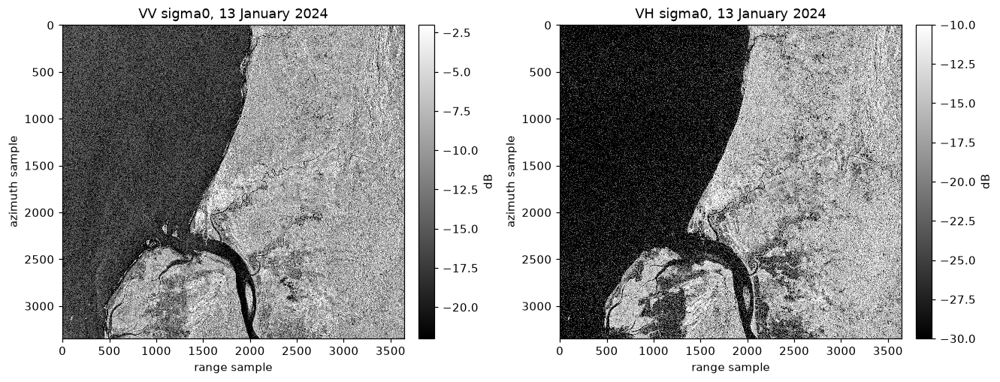

In [3]:
# Display units only. vv and vh remain linear for every index.
# Colour limits follow the bulk of this window; brighter point targets saturate.

vv_db = to_db(vv)
vh_db = to_db(vh)  # VH in dB
# converting to dB and back must return the original values
round_trip = float(np.nanmax(np.abs(from_db(vv_db) - vv)))
print(f"max |from_db(to_db(VV)) - VV|: {round_trip:.3e}")  # the largest round-trip error
print(f"VV dB  5/50/95 pct {np.round(np.nanpercentile(vv_db, [5, 50, 95]), 2)}")  # VV statistics in dB
print(f"VH dB  5/50/95 pct {np.round(np.nanpercentile(vh_db, [5, 50, 95]), 2)}")  # VH statistics in dB

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)  # two panels
draw(axes[0], vv_db, cmap="gray", vmin=-22, vmax=-2, title="VV sigma0, 13 January 2024", label="dB")  # VV in dB
# VH in dB
draw(axes[1], vh_db, cmap="gray", vmin=-30, vmax=-10, title="VH sigma0, 13 January 2024", label="dB")
plt.show()  # draw

### Cross-pol ratio, RVI, RVI4S1, RFDI, SNI, PRVI, and DPSVI

Each call is the formula from the section of the same name, applied to the linear arrays above.

| Name in the text | Function | Expression |
| --- | --- | --- |
| Cross-pol ratio | `cross_pol_ratio` | VH / VV |
| Radar Vegetation Index | `radar_vegetation_index` | 4·VH / (VV + VH) |
| RVI4S1 | `rvi4s1` | sqrt(VV / (VV + VH)) · 4·VH / (VV + VH) |
| Radar Forest Degradation Index | `radar_forest_degradation_index` | (VV - VH) / (VV + VH) |
| Sentinel Normalized Index | `sentinel_normalized_index` | (VH - VV) / (VH + VV) |
| Polarimetric RVI | `polarimetric_rvi` | (1 - VV / (VH + VV)) · VH |
| DPSVI | `dpsvi` | (VV + VH) / VV |

A NumPy array goes in and a NumPy array of the same shape comes out. No speckle filter is applied: these are the plain per-pixel formulas, and neighbouring pixels still carry speckle.

`radar_forest_degradation_index` and `sentinel_normalized_index` are the same contrast with opposite sign, so `RFDI + SNI` is zero wherever both are finite. The printed maximum absolute sum is that check.


In [4]:
# One function per index, all on the 13 January linear sigma0 window.

cr = cross_pol_ratio(vv, vh)
rvi = radar_vegetation_index(vv, vh)  # Radar Vegetation Index (dual-pol form)
rvi4 = rvi4s1(vv, vh)  # RVI4S1 variant for Sentinel-1
rfdi = radar_forest_degradation_index(vv, vh)  # Radar Forest Degradation Index
sni = sentinel_normalized_index(vv, vh)  # Sentinel Normalized Index
prvi = polarimetric_rvi(vv, vh)  # polarimetric RVI
dpsvi_val = dpsvi(vv, vh)  # Dual-Polarization SAR Vegetation Index

for name, layer in [  # statistics of every index
    ("cross-pol ratio", cr),
    ("RVI", rvi),
    ("RVI4S1", rvi4),
    ("RFDI", rfdi),
    ("SNI", sni),
    ("PRVI", prvi),
    ("DPSVI", dpsvi_val),
]:
    pct = np.nanpercentile(layer, [5, 50, 95])  # 5th, 50th and 95th percentile
    print(f"{name:16} mean {np.nanmean(layer):10.4f}   5/50/95 pct {np.round(pct, 4)}")  # one line per index

# SNI = -RFDI by definition, so their sum should be zero
print("max |SNI + RFDI| =", float(np.nanmax(np.abs(sni + rfdi))))

cross-pol ratio  mean     1.7561   5/50/95 pct [0.     0.1148 0.6   ]
RVI              mean     0.5237   5/50/95 pct [1.000e-04 4.121e-01 1.500e+00]


RVI4S1           mean     0.4483   5/50/95 pct [1.0000e-04 3.8960e-01 1.1815e+00]
RFDI             mean     0.7381   5/50/95 pct [0.25   0.794  0.9999]


SNI              mean    -0.7381   5/50/95 pct [-0.9999 -0.794  -0.25  ]
PRVI             mean     0.0041   5/50/95 pct [0.     0.0008 0.0182]


DPSVI            mean     2.7561   5/50/95 pct [1.     1.1148 1.6   ]
max |SNI + RFDI| = 0.0


### Vegetation-oriented indices

Limits are chosen from the distribution of this window so the maps show spatial structure. Pixels outside the limits saturate at the end colours.

- **RVI** on this date has a median near 0.4 and a 95th percentile near 1.5. The scale 0 to 2 covers that body. The formula can reach 4.
- **RVI4S1** is lower than RVI on the same pixels because of the extra VV weighting. The scale 0 to 1.4 covers the 95th percentile (about 1.2).
- **PRVI** still carries the magnitude of VH, so values sit near 0.001. A scale of 0 to 1 would look empty. The scale 0 to 0.03 covers the body of the distribution.
- **DPSVI** is (VV + VH) / VV, so it starts at 1 wherever VH is negligible. Most of this window falls between 1 and 1.8.

Higher RVI and RVI4S1 mark a larger share of cross-polarised scattering. Read them as relative patterns inside this acquisition. Incidence angle, soil moisture, and the mix of open water, settlement, and fields all move the number.


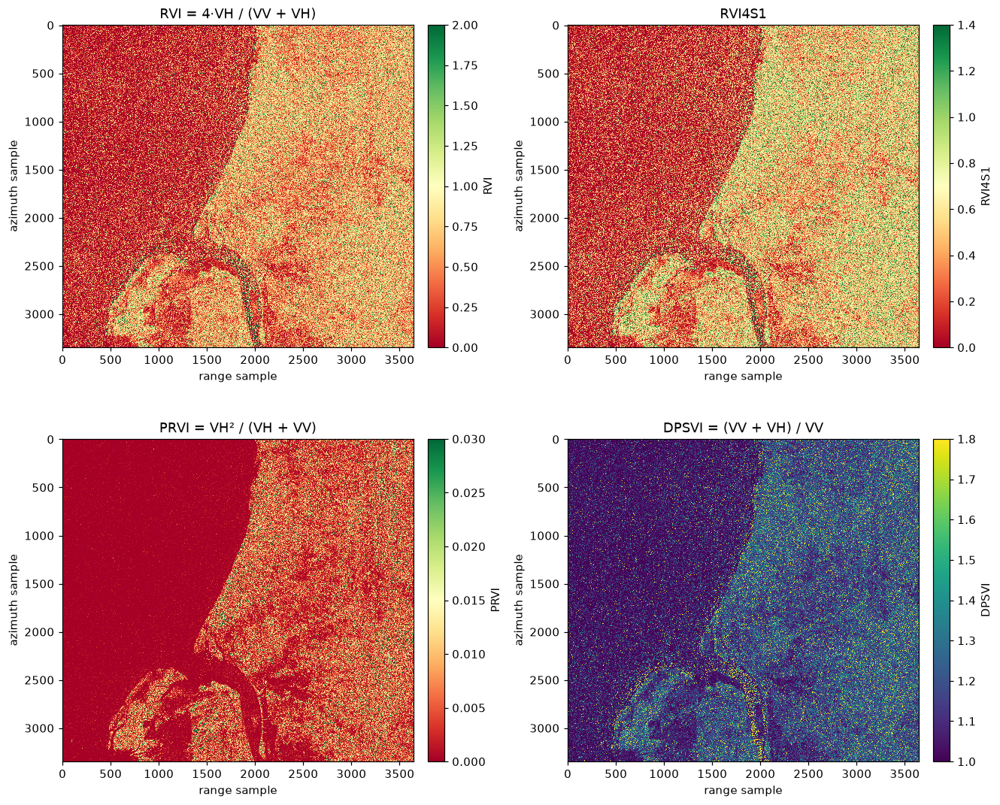

In [5]:
# Vegetation-oriented indices for 13 January 2024. Limits follow the
# distribution of this window; pixels outside the limits saturate.

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
panels = [  # index, colour map, limits, title and label of each panel
    (axes[0, 0], rvi, "RdYlGn", 0, 2, "RVI = 4·VH / (VV + VH)", "RVI"),
    (axes[0, 1], rvi4, "RdYlGn", 0, 1.4, "RVI4S1", "RVI4S1"),
    (axes[1, 0], prvi, "RdYlGn", 0, 0.03, "PRVI = VH² / (VH + VV)", "PRVI"),
    (axes[1, 1], dpsvi_val, "viridis", 1, 1.8, "DPSVI = (VV + VH) / VV", "DPSVI"),
]
for ax, layer, cmap, vmin, vmax, title, label in panels:  # every panel
    draw(ax, layer, cmap=cmap, vmin=vmin, vmax=vmax, title=title, label=label)  # draw it
plt.show()  # draw the figure

### Polarization contrast on 13 January

`radar_forest_degradation_index` and `sentinel_normalized_index` share a diverging scale from -1 to 1, so the sign flip (RFDI = -SNI) is visible as a colour reverse. On this date most of the window has positive RFDI (VV greater than VH), which is the pattern where surface scattering dominates, including open water.

`cross_pol_ratio` is the unbounded form of the same comparison, VH / VV. The scale 0 to 0.6 covers the 95th percentile of this date. Use the ratio when the quotient itself is the predictor. RFDI and SNI are the bounded versions of that contrast.


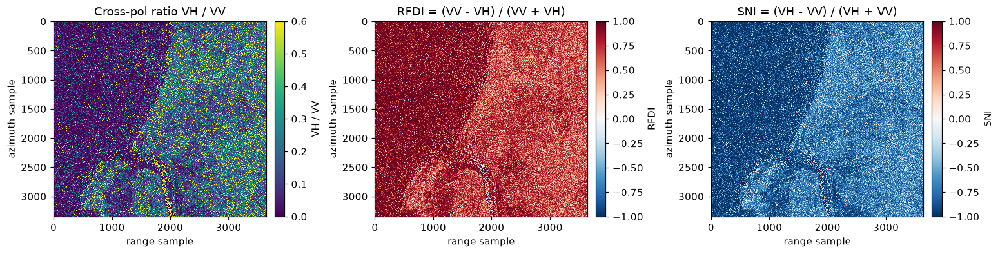

In [6]:
# Polarization contrast for 13 January. RFDI and SNI share a diverging
# scale centred on zero. The cross-pol ratio is sequential because linear
# sigma0 keeps VH / VV positive.

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
# cross-polarisation ratio
draw(axes[0], cr, cmap="viridis", vmin=0, vmax=0.6, title="Cross-pol ratio VH / VV", label="VH / VV")
draw(axes[1], rfdi, cmap="RdBu_r", vmin=-1, vmax=1, title="RFDI = (VV - VH) / (VV + VH)", label="RFDI")  # RFDI
draw(axes[2], sni, cmap="RdBu_r", vmin=-1, vmax=1, title="SNI = (VH - VV) / (VH + VV)", label="SNI")  # SNI
plt.show()  # draw

### Every single-date metric in one call

`dual_pol_indices(vv, vh)` returns the seven named indices plus the four simple metrics from the table earlier in this notebook: `vv_minus_vh`, `vv_plus_vh`, `vh_vv_ratio`, and `vv_vh_ratio`. `vh_vv_ratio` is the same quotient as `cross_pol_ratio`.

The printout gives the scene mean and the median of each layer. Ratio means sit well above the medians: a sample with VH near the noise floor makes VV/VH very large, and those samples pull the average up.


In [7]:
# The same single-date formulas, collected by dual_pol_indices.
# Useful when the layers are inputs to a later classification or model
# and you want every predictor from one call.

all_indices = dual_pol_indices(vv, vh)

print(f"{'layer':28} {'shape':16} {'mean':>12} {'median':>12}")  # header of the summary
for key, layer in all_indices.items():  # every layer returned by dual_pol_indices
    print(  # shape, mean and median
        f"{key:28} {str(layer.shape):16} "
        f"{float(np.nanmean(layer)):12.4f} {float(np.nanmedian(layer)):12.4f}"
    )

layer                        shape                    mean       median
cross_pol_ratio              (3344, 3643)           1.7561       0.1148


rvi                          (3344, 3643)           0.5237       0.4121
rvi4s1                       (3344, 3643)           0.4483       0.3896
forest_degradation_index     (3344, 3643)           0.7381       0.7940


normalized_index             (3344, 3643)          -0.7381      -0.7940
polarimetric_rvi             (3344, 3643)           0.0041       0.0008
dpsvi                        (3344, 3643)           2.7561       1.1148


vv_minus_vh                  (3344, 3643)           0.0966       0.0414
vv_plus_vh                   (3344, 3643)           0.1345       0.0693
vh_vv_ratio                  (3344, 3643)           1.7561       0.1148


vv_vh_ratio                  (3344, 3643)        4248.5298       8.7074


## Temporal change in RVI and the forest degradation index

The single Sentinel-1 pass above cannot show a change through the year. This section uses the 19-date track 77 stack in `Data/08_remote_sensing/08_03_radar/s1_rohingya_2017/`, the same relative orbit, held on one 10 m grid.

- `grd_sigma0_track77_2017.nc` is linear sigma0 with thermal noise removed. Its `calibration` attribute is `sigma0, noise removed`.
- `rtc_gamma0_track77_2017.nc` is terrain-flattened gamma0 on the same dates and the same pixels.

Both files run from 3 January to 23 November 2017. The grid is 377 by 382 pixels. Easting runs from about 409.7 to 413.5 km and northing from about 2342.2 to 2346.0 km, covering the Kutupalong-Balukhali area of Cox's Bazar.

`radar_vegetation_index` is `4·VH / (VV + VH)` and `radar_forest_degradation_index` is `(VV - VH) / (VV + VH)`. Those two expressions are one measurement written two ways:

$$\mathrm{RVI} = 2\,(1 - \mathrm{RFDI})$$

A rise in the scene-mean RVI is a fall in the scene-mean RFDI of half that size. `temporal_change(later, earlier)` is later minus earlier, applied to the index rather than to the backscatter.


### Open both stacks

`xr.open_dataset` reads each NetCDF lazily. The index functions follow the `time` dimension, so one call builds an RVI cube and an RFDI cube of shape `(time, y, x)` for each calibration. The printed maximum checks the identity above on the sigma0 stack.


In [8]:
# Track 77, 2017. sigma0 and terrain-flattened gamma0 share dates and pixels.
# RVI and RFDI are computed on every date of both stacks.

import xarray as xr

# GRD sigma0 stack of track 77, 2017 (from the multitemporal GRD notebook)
SIGMA_NC = DATA / "s1_rohingya_2017/grd_sigma0_track77_2017.nc"
# terrain-flattened gamma0 (RTC) stack of the same dates
GAMMA_NC = DATA / "s1_rohingya_2017/rtc_gamma0_track77_2017.nc"
sigma = xr.open_dataset(SIGMA_NC)  # open the sigma0 stack
gamma = xr.open_dataset(GAMMA_NC)  # open the gamma0 stack

rvi_s = radar_vegetation_index(sigma.vv, sigma.vh)  # RVI on every sigma0 date
rfdi_s = radar_forest_degradation_index(sigma.vv, sigma.vh)  # RFDI on every sigma0 date
rvi_g = radar_vegetation_index(gamma.vv, gamma.vh)  # RVI on every gamma0 date
rfdi_g = radar_forest_degradation_index(gamma.vv, gamma.vh)  # RFDI on every gamma0 date
rvi_s_mean = rvi_s.mean(dim=("y", "x"))  # scene mean of each date
rfdi_s_mean = rfdi_s.mean(dim=("y", "x"))  # scene mean of each date
rvi_g_mean = rvi_g.mean(dim=("y", "x"))  # scene mean of each date
rfdi_g_mean = rfdi_g.mean(dim=("y", "x"))  # scene mean of each date

# RVI = 2 (1 - RFDI) holds exactly for these definitions
identity = float(np.nanmax(np.abs((rvi_s - 2 * (1 - rfdi_s)).values)))
# number of dates and grid size
print(f"dates: {sigma.sizes['time']}   grid: {sigma.sizes['y']} x {sigma.sizes['x']}")
print(f"from {str(sigma.time.values[0])[:10]} to {str(sigma.time.values[-1])[:10]}")  # first and last date
print(f"sigma0 calibration: {sigma.attrs['calibration']}")  # how the sigma0 stack was calibrated
print(f"max |RVI - 2*(1 - RFDI)| on sigma0: {identity:.3e}")  # the identity check
# range of the sigma0 scene means
print(f"sigma0 RVI scene mean  {float(rvi_s_mean.min()):.3f} to {float(rvi_s_mean.max()):.3f}")
# range of the gamma0 scene means
print(f"gamma0 RVI scene mean  {float(rvi_g_mean.min()):.3f} to {float(rvi_g_mean.max()):.3f}")

/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.16) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


dates: 19   grid: 377 x 382
from 2017-01-03 to 2017-11-23
sigma0 calibration: sigma0, noise removed
max |RVI - 2*(1 - RFDI)| on sigma0: 2.682e-07
sigma0 RVI scene mean  0.756 to 0.872
gamma0 RVI scene mean  0.806 to 0.908


### Scene mean through 2017

Averaging over `y` and `x` collapses each date to one number for this window. The window mixes settlement, hillside, and fields, so the mean is a summary of the box, not a value for one land-cover class.

On the sigma0 stack the RVI mean stays near 0.8. It reaches about 0.87 on 8 June and falls to about 0.76 on 23 November. The gamma0 mean sits about 0.04 higher and follows the same rises and falls. The correlation of the two RVI series is about 0.98. The RFDI panel is the mirror required by the identity: its sigma0 mean is lowest on 8 June (about 0.56) and highest on 23 November (about 0.62).


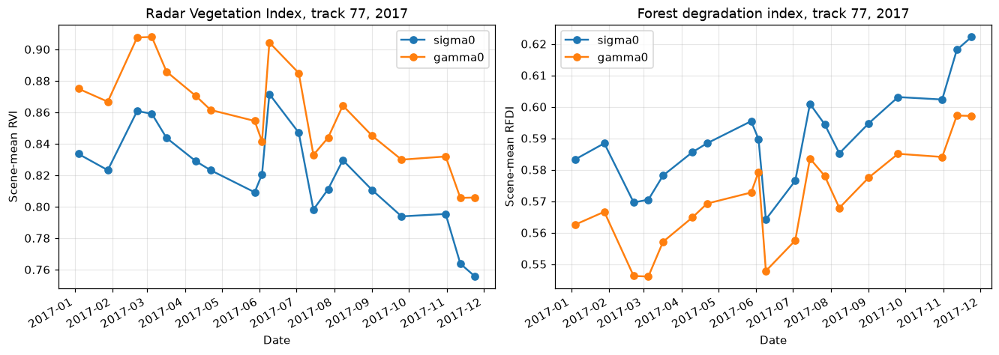

In [9]:
# One point per acquisition. Sigma0 and gamma0 are drawn together so the
# terrain-flattened series can be compared with the ellipsoid sigma0 series.
# RFDI is the algebraic mirror of RVI, so the right-hand panel moves the other way.

dates = sigma.time.values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)  # two panels
axes[0].plot(dates, rvi_s_mean.values, marker="o", linewidth=1.6, label="sigma0")  # RVI from sigma0
axes[0].plot(dates, rvi_g_mean.values, marker="o", linewidth=1.6, label="gamma0")  # RVI from gamma0
axes[0].set_ylabel("Scene-mean RVI")  # label
axes[0].set_title("Radar Vegetation Index, track 77, 2017")  # title
axes[1].plot(dates, rfdi_s_mean.values, marker="o", linewidth=1.6, label="sigma0")  # RFDI from sigma0
axes[1].plot(dates, rfdi_g_mean.values, marker="o", linewidth=1.6, label="gamma0")  # RFDI from gamma0
axes[1].set_ylabel("Scene-mean RFDI")  # label
axes[1].set_title("Forest degradation index, track 77, 2017")  # title
for ax in axes:  # for both panels
    ax.set_xlabel("Date")  # x label
    ax.grid(True, alpha=0.3)  # grid
    ax.legend()  # legend
fig.autofmt_xdate()  # slanted date labels
plt.show()  # draw

### January to November on the sigma0 stack

`temporal_change` subtracts the 3 January index from the 23 November index at each pixel. The median RVI change on sigma0 is about -0.08, and the median RFDI change is about +0.04. That pair matches the identity: the RFDI change is minus one half of the RVI change.

The scales are ±1 for RVI and ±0.5 for RFDI, so a pixel and its algebraic partner land on the same colour. Blue on the RVI map is a loss of cross-polarised share. Red on the RFDI map is the same loss. The 5th to 95th percentile of the RVI change runs from about -0.95 to 0.81, so the scale covers the body of the distribution and the tails saturate.

The gamma0 stack gives almost the same January-to-November shift: a mean RVI change of about -0.07, against about -0.08 for sigma0. The maps below are the sigma0 change. Terrain flattening moves the level of the index and leaves the seasonal change in the same direction.


sigma0  RVI change   mean -0.078   median -0.082
sigma0  RFDI change  mean  0.039   median  0.041
gamma0  RVI change   mean -0.069   median -0.073
gamma0  RFDI change  mean  0.035   median  0.037


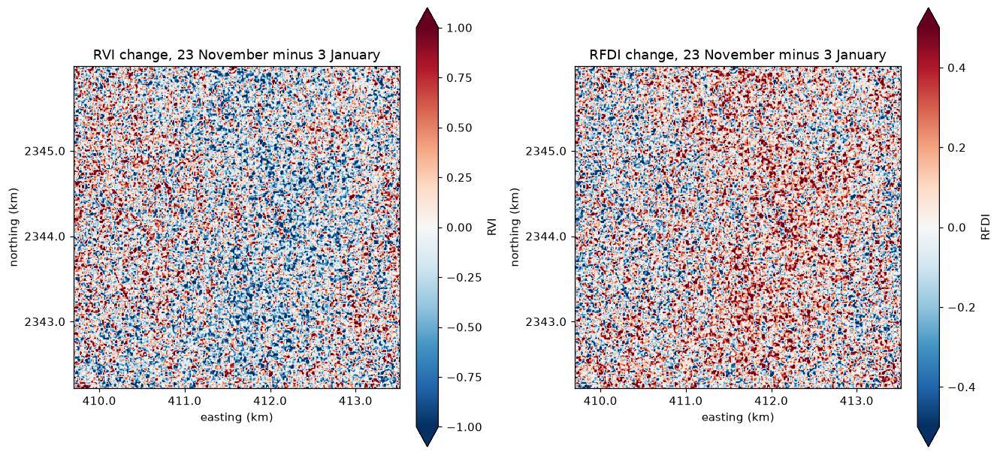

In [10]:
# First date against the last on the sigma0 stack. The RFDI scale is half
# the RVI scale and runs the other way, matching RVI = 2*(1 - RFDI).

import matplotlib.ticker as mticker

rvi_change = temporal_change(rvi_s.isel(time=-1), rvi_s.isel(time=0))  # RVI change, last date minus first date
rfdi_change = temporal_change(rfdi_s.isel(time=-1), rfdi_s.isel(time=0))  # RFDI change
rvi_change_g = temporal_change(rvi_g.isel(time=-1), rvi_g.isel(time=0))  # the same on gamma0
rfdi_change_g = temporal_change(rfdi_g.isel(time=-1), rfdi_g.isel(time=0))  # the same on gamma0

# statistics of the changes
print(f"sigma0  RVI change   mean {float(rvi_change.mean()): .3f}   median {float(rvi_change.median()): .3f}")
# statistics of the changes
print(f"sigma0  RFDI change  mean {float(rfdi_change.mean()): .3f}   median {float(rfdi_change.median()): .3f}")
# statistics of the changes
print(f"gamma0  RVI change   mean {float(rvi_change_g.mean()): .3f}   median {float(rvi_change_g.median()): .3f}")
# statistics of the changes
print(f"gamma0  RFDI change  mean {float(rfdi_change_g.mean()): .3f}   median {float(rfdi_change_g.median()): .3f}")


# helper that draws a north-up map with kilometre ticks
def draw_map(ax, layer, *, cmap, vmin, vmax, title, label):
    """One north-up panel. Axis ticks are kilometres on the stack grid."""
    # the layer with a colour bar
    layer.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, cbar_kwargs={"label": label})
    ax.set_title(title)  # title
    ax.set_aspect("equal")  # equal scale on both axes
    # metres -> kilometres on the tick labels
    km = mticker.FuncFormatter(lambda value, _pos: f"{value / 1000:.1f}")
    ax.xaxis.set_major_formatter(km)  # x ticks in km
    ax.yaxis.set_major_formatter(km)  # y ticks in km
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))  # about four x ticks
    ax.yaxis.set_major_locator(mticker.MaxNLocator(4))  # about four y ticks
    ax.set_xlabel("easting (km)")  # x label
    ax.set_ylabel("northing (km)")  # y label


fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)  # two panels
draw_map(axes[0], rvi_change, cmap="RdBu_r", vmin=-1, vmax=1,  # RVI change
         title="RVI change, 23 November minus 3 January", label="RVI")
draw_map(axes[1], rfdi_change, cmap="RdBu_r", vmin=-0.5, vmax=0.5,  # RFDI change
         title="RFDI change, 23 November minus 3 January", label="RFDI")
plt.show()  # draw

### Change between two dates

`temporal_change(later, earlier)` is the linear difference later minus earlier. `temporal_ratio(later, earlier)` is later divided by earlier. A difference of 0 and a ratio of 1 both mean the channel was unchanged. The change in decibels is `to_db(later) - to_db(earlier)`, which equals `10·log10` of the temporal ratio.

The Sentinel-1 window above is one pass. These two functions are applied instead to a pair of RADARSAT-2 detected products that share HH and HV:

- 16 November 2023, Standard beam S3, `Data/08_remote_sensing/08_03_radar/s1_rohingya_2017/RS2_OK153952_PK1408402_DK1372521_S3_20231116_052449_HH_HV_SGF`. Incidence angle about 30.6 to 37.1 degrees. Pixel spacing 12.5 m.
- 30 November 2023, Wide beam W3, `Data/08_remote_sensing/08_03_radar/RS2_OK153952_PK1408405_DK1372524_W3_20231130_051625_HH_HV_SGF`. Incidence angle about 38.8 to 45.3 degrees. Same pixel spacing.

Both are SGF GeoTIFFs: magnitude detected, ground range, with a sigma-nought gain in `lutSigma.xml` (one value per range sample, offset 0). Calibration is `sigma0 = DN^2 / gain`. The scenes cover northern Germany, about 52.8 to 53.9 N and 12.0 to 13.9 E, which does not overlap the Cox's Bazar window. The common box used below is `(13.10, 53.30, 13.40, 53.55)`.

The two beams are not the same viewing geometry. A lower sigma0 on 30 November is expected from the higher incidence angle of the Wide beam, even where the surface did not change. Read the maps as the output of the two functions, and treat the overall darkening as a beam effect. Local departures from that shift are the part that can be a real change in the surface, mixed with speckle.


### Read and calibrate both RADARSAT-2 passes

Each polarisation is cropped to the lon/lat box with the product ground-control points, then divided by the gain samples that belong to those range columns. `create_stack` warps the two dates of one polarisation onto one 40 m grid with those same ground-control points, so `temporal_change` and `temporal_ratio` see aligned pixels. Thermal noise is left in: these SGF products store a reference noise level, and this cell does not subtract it.


In [11]:
# Two RADARSAT-2 HH/HV dates, calibrated to linear sigma0 and warped
# onto one grid. temporal_change and temporal_ratio then compare 30 November
# with 16 November, polarisation by polarisation.

import xml.etree.ElementTree as ET

import rasterio  # raster reading
from rasterio.control import GroundControlPoint  # ground control point record
from rasterio.transform import from_gcps  # affine transform from GCPs
from rasterio.windows import Window  # read a pixel window

# RADARSAT-2 HH/HV scene of 16 November 2023
S3 = DATA / "s1_rohingya_2017/RS2_OK153952_PK1408402_DK1372521_S3_20231116_052449_HH_HV_SGF"
# RADARSAT-2 HH/HV scene of 30 November 2023
W3 = DATA / "RS2_OK153952_PK1408405_DK1372524_W3_20231130_051625_HH_HV_SGF"
RS2_AOI = (13.10, 53.30, 13.40, 53.55)  # west, south, east, north


def read_rs2_sigma0(product, pol, bounds):  # calibrated sigma0 of one polarisation inside a lon/lat box
    """Sigma0 for one RADARSAT-2 SGF polarisation inside a lon/lat box."""
    root = ET.parse(product / "lutSigma.xml").getroot()  # the sigma0 look-up table
    offset = float(root.find("offset").text)  # its offset
    gains = np.array(root.find("gains").text.split(), dtype="float64")  # its gains (one per range column)
    with rasterio.open(product / f"imagery_{pol}.tif") as src:  # open the image of this polarisation
        gcps, gcp_crs = src.gcps  # its GCPs and their CRS
        inverse = ~from_gcps(gcps)  # inverse of the GCP-fitted transform: map -> pixel
        west, south, east, north = bounds  # the box
        cols, rows = zip(*[inverse * (x, y) for x, y in  # pixel position of each corner
                           [(west, south), (east, south), (west, north), (east, north)]])
        row0 = max(0, int(np.floor(min(rows))) - 20)  # first row (with a 20-pixel margin)
        col0 = max(0, int(np.floor(min(cols))) - 20)  # first column
        row1 = min(src.height, int(np.ceil(max(rows))) + 20)  # last row
        col1 = min(src.width, int(np.ceil(max(cols))) + 20)  # last column
        dn = src.read(1, window=Window(col0, row0, col1 - col0, row1 - row0))  # read the window
    gain = gains[col0:col0 + dn.shape[1]]  # gains of the window's columns
    # sigma0 = (DN² + offset) / gain
    sigma = (dn.astype("float32") ** 2 + np.float32(offset)) / gain[np.newaxis, :]
    sigma = np.where(dn > 0, sigma, np.nan).astype("float32")  # zero DN is no data
    near = [g for g in gcps  # GCPs near the window
            if row0 - 400 <= g.row <= row0 + dn.shape[0] + 400
            and col0 - 400 <= g.col <= col0 + dn.shape[1] + 400]
    # GCPs shifted into the window's own pixel numbering
    local = [GroundControlPoint(row=g.row - row0, col=g.col - col0, x=g.x, y=g.y, z=g.z)
             for g in near]
    return {"data": sigma, "gcps": local, "gcp_crs": gcp_crs}  # sigma0 and its GCPs


hh = s1_sar.create_stack(  # HH of both dates on one common grid
    [read_rs2_sigma0(S3, "HH", RS2_AOI), read_rs2_sigma0(W3, "HH", RS2_AOI)],
    ["2023-11-16", "2023-11-30"], bounds=RS2_AOI, resolution=40, name="hh",
)
hv = s1_sar.create_stack(  # HV of both dates on one common grid
    [read_rs2_sigma0(S3, "HV", RS2_AOI), read_rs2_sigma0(W3, "HV", RS2_AOI)],
    ["2023-11-16", "2023-11-30"], bounds=RS2_AOI, resolution=40, name="hv",
)
hh_early, hh_late = hh.isel(time=0), hh.isel(time=1)  # HH of each date
hv_early, hv_late = hv.isel(time=0), hv.isel(time=1)  # HV of each date

hh_change = temporal_change(hh_late, hh_early)  # linear change (late minus early)
hv_change = temporal_change(hv_late, hv_early)  # same for HV
hh_ratio = temporal_ratio(hh_late, hh_early)  # ratio late / early
hv_ratio = temporal_ratio(hv_late, hv_early)  # same for HV
hh_change_db = to_db(hh_late) - to_db(hh_early)  # change in dB
hv_change_db = to_db(hv_late) - to_db(hv_early)  # same for HV

print("grid", tuple(hh.sizes[d] for d in ("time", "y", "x")))  # grid size
# statistics of the changes
print(f"HH linear change  mean {float(hh_change.mean()): .4f}   median {float(hh_change.median()): .4f}")
# statistics of the changes
print(f"HV linear change  mean {float(hv_change.mean()): .4f}   median {float(hv_change.median()): .4f}")
# statistics of the ratios
print(f"HH ratio          mean {float(hh_ratio.mean()): .3f}   median {float(hh_ratio.median()): .3f}")
# statistics of the ratios
print(f"HV ratio          mean {float(hv_ratio.mean()): .3f}   median {float(hv_ratio.median()): .3f}")
# statistics in dB
print(f"HH change (dB)    mean {float(hh_change_db.mean()): .2f}   median {float(hh_change_db.median()): .2f}")
# statistics in dB
print(f"HV change (dB)    mean {float(hv_change_db.mean()): .2f}   median {float(hv_change_db.median()): .2f}")

grid (2, 709, 516)
HH linear change  mean -0.0920   median -0.0773
HV linear change  mean -0.0179   median -0.0167
HH ratio          mean  0.544   median  0.484
HV ratio          mean  0.564   median  0.478
HH change (dB)    mean -3.26   median -3.15
HV change (dB)    mean -3.12   median -3.20


### Where the backscatter changed

The top row is sigma0 in decibels for HH on the two dates, on one grey scale. The 30 November image is darker across the window. That matches the printed median change of about -3 dB and the higher incidence angle of the Wide beam.

The bottom row is the decibel difference, 30 November minus 16 November, diverging about zero. Blue is a decrease, red is an increase, and the scale -8 to 2 dB covers the body of both polarisations. Because the typical pixel sits near -3 dB, most of the map is blue. Patches that are lighter or darker than their neighbours are the places where the ratio is not just the beam shift.


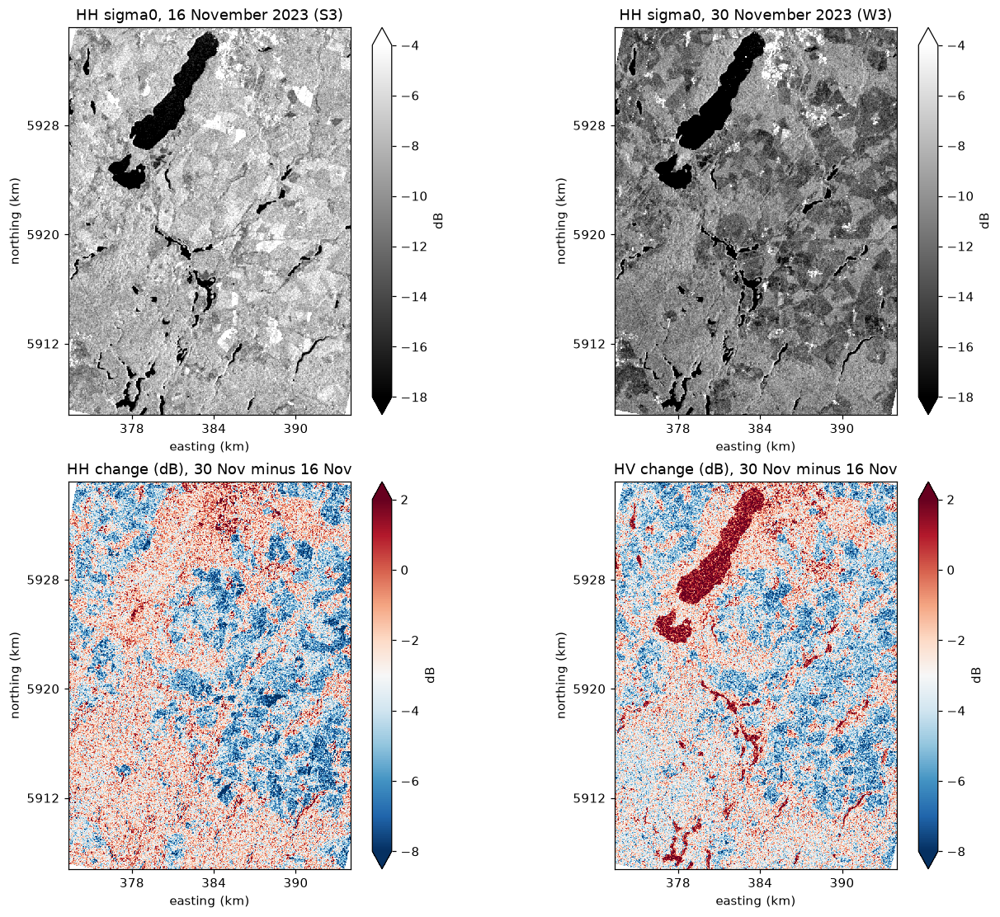

In [12]:
# 16 November against 30 November. Top: HH in dB on a shared scale.
# Bottom: decibel difference, later minus earlier, diverging about zero.

import matplotlib.ticker as mticker


# helper that draws a north-up map with kilometre ticks
def draw_map(ax, layer, *, cmap, vmin, vmax, title, label):
    """One north-up panel. Axis ticks are kilometres on the common grid."""
    # the layer with a colour bar
    layer.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, cbar_kwargs={"label": label})
    ax.set_title(title)  # title
    ax.set_aspect("equal")  # equal scale on both axes
    # metres -> kilometres on the tick labels
    km = mticker.FuncFormatter(lambda value, _pos: f"{value / 1000:.0f}")
    ax.xaxis.set_major_formatter(km)  # x ticks in km
    ax.yaxis.set_major_formatter(km)  # y ticks in km
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))  # about four x ticks
    ax.yaxis.set_major_locator(mticker.MaxNLocator(4))  # about four y ticks
    ax.set_xlabel("easting (km)")  # x label
    ax.set_ylabel("northing (km)")  # y label


fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)  # 2 x 2 panels
draw_map(axes[0, 0], to_db(hh_early), cmap="gray", vmin=-18, vmax=-4,  # HH on the first date
         title="HH sigma0, 16 November 2023 (S3)", label="dB")
draw_map(axes[0, 1], to_db(hh_late), cmap="gray", vmin=-18, vmax=-4,  # HH on the second date
         title="HH sigma0, 30 November 2023 (W3)", label="dB")
draw_map(axes[1, 0], hh_change_db, cmap="RdBu_r", vmin=-8, vmax=2,  # HH change in dB
         title="HH change (dB), 30 Nov minus 16 Nov", label="dB")
draw_map(axes[1, 1], hv_change_db, cmap="RdBu_r", vmin=-8, vmax=2,  # HV change in dB
         title="HV change (dB), 30 Nov minus 16 Nov", label="dB")
plt.show()  # draw

### Temporal ratio

`temporal_ratio` is later divided by earlier, so 1 means the linear sigma0 was unchanged. On this pair the median ratio is about 0.5 for both HH and HV: the Wide-beam backscatter is about half the Standard-beam backscatter. The scale runs from 0.2 to 1.2, which covers the 5th to 95th percentile of HH and most of HV. A ratio of 1 sits near the top of that scale.


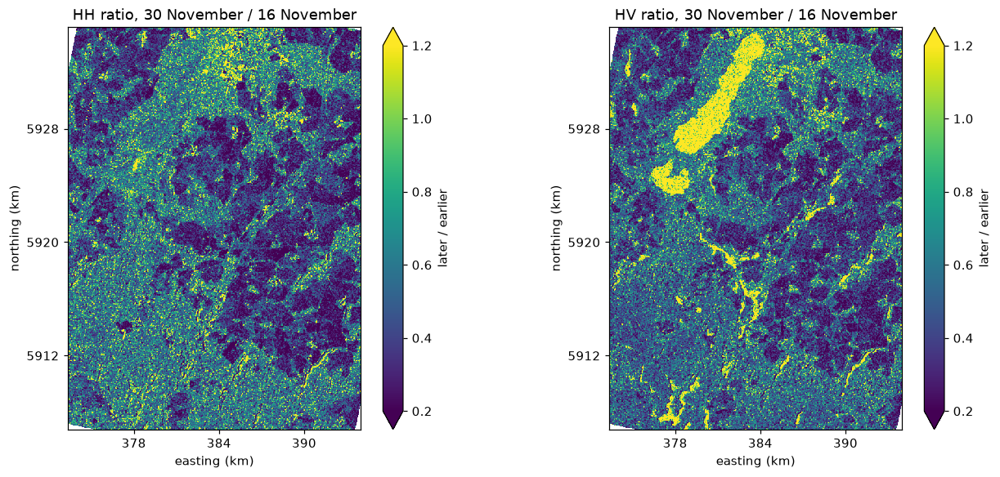

In [13]:
# Linear ratio, 30 November / 16 November. The scale covers the bulk of
# the HH distribution. Values above 1.2 take the top colour.

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
draw_map(axes[0], hh_ratio, cmap="viridis", vmin=0.2, vmax=1.2,  # HH ratio
         title="HH ratio, 30 November / 16 November", label="later / earlier")
draw_map(axes[1], hv_ratio, cmap="viridis", vmin=0.2, vmax=1.2,  # HV ratio
         title="HV ratio, 30 November / 16 November", label="later / earlier")
plt.show()  # draw

## Recommended reading and technical references

- Copernicus Data Space Ecosystem: [Sentinel data and processing documentation](https://documentation.dataspace.copernicus.eu/).

- [Copernicus Sentinel-1 Radar Vegetation Index tutorial](https://documentation.dataspace.copernicus.eu/APIs/openEO/openeo-community-examples/python/50_thematic-notebooks/radar-vegetation-index/radar-vegetation-index.html): practical RVI calculations in Python.


- [ArcGIS SAR Indices documentation](https://pro.arcgis.com/en/pro-app/latest/help/analysis/raster-functions/sar-indices-function.htm): RVI, RFDI, and CSI definitions and input requirements.


- [Sentinel-1 time-series indices for agricultural management zones](https://www.mdpi.com/2624-7402/7/5/150): examples of SAR-derived agricultural indices.
